In [68]:
## 1. ASK
## How many days last season had optimal conditions for snowmaking?
## Estimate the electricity budget required to run all snowmaking equipment for every hour with optimal conditions.
## Graph all days of the season using a heatmap.
## Color all days with a gradient according to the conditions for snowmaking. Use facets to separate each month.
## Graph all snow that fell naturally last season using a line.

## 2. PREPARE / RESEARCH
## The winter season is November 1, 2024 - March 31, 2025
## Assuming trails open at 9AM and close at 4:30PM
## Snowmaking crews work for 16.5 hours
## To make snow, temperature must be 27 degrees Farenheit and below
## Humidity must be low between 30% and 60%
## Snowshoe mountain is equipped with 75 DemacLenko Titan 2.0 fixed position tower fan guns.
## 90 low-energy "stick" guns which use 10% of the energy.

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [70]:
import sys
print(sys.version)
print('pandas version', pd.__version__)

3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
pandas version 2.2.3


In [71]:
## This dataset provided by the NCEI or National Centers for Environmental Information has a record of daily snowfall totals.
## As provided, this table has a title. I'm going to include a parameter header=1 to begin the index on the second row.

In [72]:
df = pd.read_csv("C:/Users/Spencer Woo/Downloads/data(9).csv", header=1)

In [73]:
#pd.set_option('display_max_rows')
#pd.set_option('display_max_columns')
pd.reset_option('display_max_rows')
pd.reset_option('display_max_columns')

OptionError: No such keys(s)

In [74]:
df

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
0,1975-02-01,NaN,40.0,31.0,0.46,0.0,0.0
1,1975-02-02,NaN,34.0,27.0,0.40,4.0,4.0
2,1975-02-03,NaN,36.0,19.0,0.00,0.0,NaN
3,1975-02-04,NaN,30.0,14.0,0.00,0.0,NaN
4,1975-02-05,NaN,45.0,17.0,1.18,15.0,17.0
...,...,...,...,...,...,...,...
18571,2025-12-06,NaN,27.0,18.0,0.01,0.5,3.0
18572,2025-12-07,NaN,30.0,17.0,0.00,0.0,NaN
18573,2025-12-08,NaN,35.0,19.0,0.01,0.2,3.0
18574,2025-12-09,NaN,26.0,14.0,0.30,2.0,5.0


In [75]:
df.shape

(18576, 7)

In [76]:
df.head()

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
0,1975-02-01,NaN,40.0,31.0,0.46,0.0,0.0
1,1975-02-02,NaN,34.0,27.0,0.40,4.0,4.0
2,1975-02-03,NaN,36.0,19.0,0.00,0.0,NaN
3,1975-02-04,NaN,30.0,14.0,0.00,0.0,NaN
4,1975-02-05,NaN,45.0,17.0,1.18,15.0,17.0


In [77]:
df.dtypes

Date                          object
TAVG (Degrees Fahrenheit)    float64
TMAX (Degrees Fahrenheit)    float64
TMIN (Degrees Fahrenheit)    float64
PRCP (Inches)                float64
SNOW (Inches)                float64
SNWD (Inches)                float64
dtype: object

In [78]:
## df.plot()

In [79]:
## Notice the table has two separate columns for snowfall and snow depth
## Remember, we are looking for snowfall and not snow depth

In [80]:
df.columns

Index(['Date', 'TAVG (Degrees Fahrenheit)', 'TMAX (Degrees Fahrenheit)',
       'TMIN (Degrees Fahrenheit)', 'PRCP (Inches)', 'SNOW (Inches)',
       'SNWD (Inches)'],
      dtype='object')

In [81]:
## Copy and paste the results of df.columns into double brackets to take a subset of the data

In [82]:
df[['Date','SNOW (Inches)']]

,Date,SNOW (Inches)
0,1975-02-01,0.0
1,1975-02-02,4.0
2,1975-02-03,0.0
3,1975-02-04,0.0
4,1975-02-05,15.0
...,...,...
18571,2025-12-06,0.5
18572,2025-12-07,0.0
18573,2025-12-08,0.2
18574,2025-12-09,2.0


In [83]:
## This dataset is 18,576 rows long
## I only need the '24-'25 winter season as a subset
## Start of season is November 11 or index 18171

In [84]:
df.loc[df['Date']=='2024-11-01']

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18171,2024-11-01,NaN,72.0,49.0,0.0,0.0,0.0


In [85]:
## End of season is March 30 or index 18351

In [86]:
df.loc[df['Date']=='2025-04-30']

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18351,2025-04-30,NaN,75.0,44.0,0.2,0.0,0.0


In [87]:
## and then filter only the relevant data from the set using the indices as a range

In [88]:
df.iloc[18171:18351]

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18171,2024-11-01,NaN,72.0,49.0,0.00,0.0,0.0
18172,2024-11-02,NaN,56.0,34.0,0.10,0.0,0.0
18173,2024-11-03,NaN,59.0,30.0,0.00,0.0,0.0
18174,2024-11-04,NaN,60.0,32.0,0.00,0.0,0.0
18175,2024-11-05,NaN,59.0,37.0,0.00,0.0,0.0
...,...,...,...,...,...,...,...
18346,2025-04-25,NaN,69.0,42.0,0.00,0.0,0.0
18347,2025-04-26,NaN,62.0,52.0,0.55,0.0,0.0
18348,2025-04-27,NaN,56.0,30.0,0.25,0.0,0.0
18349,2025-04-28,NaN,58.0,28.0,0.00,0.0,0.0


In [89]:
## This really demonstrates the utility of the query method
## The same comparisons with loc and iloc can be written in one phrase using query

In [90]:
df.query("Date >= '2024-11-01' and Date <= '2025-04-30'")

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18171,2024-11-01,NaN,72.0,49.0,0.00,0.0,0.0
18172,2024-11-02,NaN,56.0,34.0,0.10,0.0,0.0
18173,2024-11-03,NaN,59.0,30.0,0.00,0.0,0.0
18174,2024-11-04,NaN,60.0,32.0,0.00,0.0,0.0
18175,2024-11-05,NaN,59.0,37.0,0.00,0.0,0.0
...,...,...,...,...,...,...,...
18347,2025-04-26,NaN,62.0,52.0,0.55,0.0,0.0
18348,2025-04-27,NaN,56.0,30.0,0.25,0.0,0.0
18349,2025-04-28,NaN,58.0,28.0,0.00,0.0,0.0
18350,2025-04-29,NaN,69.0,29.0,0.00,0.0,0.0


In [91]:
## Save this query as a subset of the original dataset without modifying the original

In [92]:
ss = df.query("Date >= '2024-11-01' and Date <= '2025-04-30'")

In [93]:
ss

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18171,2024-11-01,NaN,72.0,49.0,0.00,0.0,0.0
18172,2024-11-02,NaN,56.0,34.0,0.10,0.0,0.0
18173,2024-11-03,NaN,59.0,30.0,0.00,0.0,0.0
18174,2024-11-04,NaN,60.0,32.0,0.00,0.0,0.0
18175,2024-11-05,NaN,59.0,37.0,0.00,0.0,0.0
...,...,...,...,...,...,...,...
18347,2025-04-26,NaN,62.0,52.0,0.55,0.0,0.0
18348,2025-04-27,NaN,56.0,30.0,0.25,0.0,0.0
18349,2025-04-28,NaN,58.0,28.0,0.00,0.0,0.0
18350,2025-04-29,NaN,69.0,29.0,0.00,0.0,0.0


In [94]:
## 17 days are missing daily snowfall

In [95]:
ss.isna().sum()

Date                           0
TAVG (Degrees Fahrenheit)    181
TMAX (Degrees Fahrenheit)      1
TMIN (Degrees Fahrenheit)      2
PRCP (Inches)                  3
SNOW (Inches)                 17
SNWD (Inches)                 16
dtype: int64

In [96]:
ss['SNOW (Inches)'].isna().sum()

np.int64(17)

In [97]:
## I'd like to take a closer look at the rows with missing data
## The query method won't allow spaces in column names
## I'm going to remove the parentheses as well

In [98]:
ss.columns

Index(['Date', 'TAVG (Degrees Fahrenheit)', 'TMAX (Degrees Fahrenheit)',
       'TMIN (Degrees Fahrenheit)', 'PRCP (Inches)', 'SNOW (Inches)',
       'SNWD (Inches)'],
      dtype='object')

In [99]:
ss.rename(columns={'TAVG (Degrees Fahrenheit)': 'TAVG', 'TMAX (Degrees Fahrenheit)':'TMAX',
       'TMIN (Degrees Fahrenheit)':'TMIN', 'PRCP (Inches)':'PRCP', 'SNOW (Inches)':'SNOW',
       'SNWD (Inches)':'SNWD'})

,Date,TAVG,TMAX,TMIN,PRCP,SNOW,SNWD
18171,2024-11-01,NaN,72.0,49.0,0.00,0.0,0.0
18172,2024-11-02,NaN,56.0,34.0,0.10,0.0,0.0
18173,2024-11-03,NaN,59.0,30.0,0.00,0.0,0.0
18174,2024-11-04,NaN,60.0,32.0,0.00,0.0,0.0
18175,2024-11-05,NaN,59.0,37.0,0.00,0.0,0.0
...,...,...,...,...,...,...,...
18347,2025-04-26,NaN,62.0,52.0,0.55,0.0,0.0
18348,2025-04-27,NaN,56.0,30.0,0.25,0.0,0.0
18349,2025-04-28,NaN,58.0,28.0,0.00,0.0,0.0
18350,2025-04-29,NaN,69.0,29.0,0.00,0.0,0.0


In [100]:
## the query method will not accept spaces in the column name unless you wrap it in backticks

In [101]:
data = {
    'Date':['2024-12-09', '2024-12-10', '2024-12-11', '2024-12-13', '2024-12-15', '2024-12-17', '2024-12-18', '2024-12-19', '2024-12-25', '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29', '2024-12-30', '2024-12-31', '2025-02-07', '2025-02-13'],
    'SNOW (Inches)':[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
}


ss2 = pd.DataFrame(data)

In [102]:
ss2.dtypes


Date             object
SNOW (Inches)     int64
dtype: object

In [103]:
dtypes = {
    'Date':object,
    'SNOW (Inches)': float
}
ss2 = ss2.astype(dtypes)

In [104]:
ss2.dtypes

Date              object
SNOW (Inches)    float64
dtype: object

In [105]:
ss2.merge(ss)

,Date,SNOW (Inches),TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNWD (Inches)


In [106]:
ss.query('`SNOW (Inches)`.isna()')

,Date,TAVG (Degrees Fahrenheit),TMAX (Degrees Fahrenheit),TMIN (Degrees Fahrenheit),PRCP (Inches),SNOW (Inches),SNWD (Inches)
18209,2024-12-09,NaN,41.0,31.0,0.10,NaN,1.0
18210,2024-12-10,NaN,47.0,31.0,0.25,NaN,NaN
18211,2024-12-11,NaN,49.0,30.0,0.30,NaN,NaN
18213,2024-12-13,NaN,25.0,14.0,0.00,NaN,1.0
18215,2024-12-15,NaN,40.0,20.0,0.00,NaN,NaN
18217,2024-12-17,NaN,46.0,31.0,0.10,NaN,NaN
18218,2024-12-18,NaN,46.0,33.0,0.01,NaN,NaN
18219,2024-12-19,NaN,NaN,NaN,NaN,NaN,NaN
18225,2024-12-25,NaN,30.0,26.0,0.00,NaN,NaN
18226,2024-12-26,NaN,37.0,24.0,0.00,NaN,NaN


In [107]:
ss.loc[ss['SNOW (Inches)'] == 'NaN', 'SNOW (Inches)'] = 0

In [108]:
ss.query("SNOW.isna()")

UndefinedVariableError: name 'SNOW' is not defined

In [109]:
ss[['Date', 'SNOW (Inches)']]

,Date,SNOW (Inches)
18171,2024-11-01,0.0
18172,2024-11-02,0.0
18173,2024-11-03,0.0
18174,2024-11-04,0.0
18175,2024-11-05,0.0
...,...,...
18347,2025-04-26,0.0
18348,2025-04-27,0.0
18349,2025-04-28,0.0
18350,2025-04-29,0.0


<Axes: xlabel='Date'>

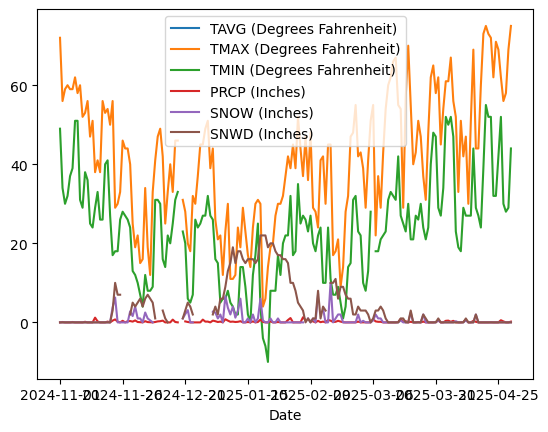

In [110]:
ss.plot('Date', kind='line')

In [111]:
## what if we found another dataset and cross referenced to fill in the blanks?
## this is why it is important to explore the data for nulls before you graph.

## this graph is difficult to read, I think it would be better to separate this graph into facets by month.

In [112]:
## There are 17 rows missing the daily snowfall total.

In [113]:
df[['TAVG (Degrees Fahrenheit)', 'SNOW (Inches)']].agg(['mean', 'min', 'max'])

,TAVG (Degrees Fahrenheit),SNOW (Inches)
mean,NaN,0.403174
min,NaN,0.000000
max,NaN,26.000000


In [114]:
del ss

In [115]:
## This is a dataset from WeatherUnderground, they keep historical weather data from the timeframe we need.
## The reason I chose this dataset is the humidity column.
## The data is also very precise, with observations being roughly an hour apart.


In [116]:
el = pd.read_csv("C:/Users/Spencer Woo/Downloads/Elkins-Randolph County Regional Airport Station - Sheet1.csv")

In [117]:
el

,Date,Time,Temperature,Dew Point,Humidity,Wind,Wind Speed,Wind Gust,Pressure,Precip.,Condition
0,11-01-2024,11:51 PM,68 °F,51 °F,55 %,S,7 mph,0 mph,27.98 in,0.0 in,Cloudy
1,11-01-2024,12:51 AM,67 °F,52 °F,59 %,S,9 mph,0 mph,27.98 in,0.0 in,Cloudy
2,11-01-2024,1:51 AM,67 °F,53 °F,61 %,S,6 mph,0 mph,27.97 in,0.0 in,Cloudy
3,11-01-2024,2:51 AM,66 °F,56 °F,70 %,W,7 mph,0 mph,27.98 in,0.0 in,Cloudy
4,11-01-2024,3:51 AM,65 °F,57 °F,75 %,WSW,6 mph,0 mph,27.99 in,0.0 in,Light Rain
...,...,...,...,...,...,...,...,...,...,...,...
5225,03-31-2025,8:51 PM,49 °F,48 °F,97 %,NW,13 mph,22 mph,27.71 in,0.0 in,Light Rain
5226,03-31-2025,9:01 PM,49 °F,48 °F,97 %,NW,13 mph,0 mph,27.71 in,0.0 in,Light Rain
5227,03-31-2025,9:30 PM,47 °F,45 °F,93 %,NW,10 mph,23 mph,27.73 in,0.0 in,Light Rain
5228,03-31-2025,9:51 PM,46 °F,44 °F,93 %,WNW,8 mph,23 mph,27.75 in,0.0 in,Light Rain


In [118]:
el.columns

Index(['Date', 'Time', 'Temperature', 'Dew Point', 'Humidity', 'Wind',
       'Wind Speed', 'Wind Gust', 'Pressure', 'Precip.', 'Condition'],
      dtype='object')

In [119]:
## Remember, the conditions for making snow are a temperature 27 Degrees Farenheit and below. Humidity must be between 30 and 60 percent.

In [120]:
el[['Date', 'Time', 'Temperature', 'Humidity']]

,Date,Time,Temperature,Humidity
0,11-01-2024,11:51 PM,68 °F,55 %
1,11-01-2024,12:51 AM,67 °F,59 %
2,11-01-2024,1:51 AM,67 °F,61 %
3,11-01-2024,2:51 AM,66 °F,70 %
4,11-01-2024,3:51 AM,65 °F,75 %
...,...,...,...,...
5225,03-31-2025,8:51 PM,49 °F,97 %
5226,03-31-2025,9:01 PM,49 °F,97 %
5227,03-31-2025,9:30 PM,47 °F,93 %
5228,03-31-2025,9:51 PM,46 °F,93 %


In [121]:
## This is every observation of the season where snowmaking was possible.

In [122]:
el.query("Temperature <= '27' and Humidity >= '30' and Humidity <= '60'")

,Date,Time,Temperature,Dew Point,Humidity,Wind,Wind Speed,Wind Gust,Pressure,Precip.,Condition
1114,11-30-2024,5:51 PM,24 °F,11 °F,57 %,SSW,3 mph,0 mph,28.00 in,0.0 in,Fair
1115,11-30-2024,6:51 PM,24 °F,10 °F,55 %,SSW,5 mph,0 mph,28.01 in,0.0 in,Fair
1169,12-01-2024,9:51 PM,22 °F,9 °F,58 %,W,5 mph,0 mph,28.05 in,0.0 in,Fair
1337,12-07-2024,9:51 AM,25 °F,11 °F,55 %,S,5 mph,0 mph,28.12 in,0.0 in,Mostly Cloudy
1543,12-12-2024,6:51 AM,26 °F,13 °F,58 %,WSW,14 mph,29 mph,28.06 in,0.0 in,Fair
...,...,...,...,...,...,...,...,...,...,...,...
4420,03-02-2025,9:51 AM,22 °F,7 °F,53 %,NW,7 mph,0 mph,28.06 in,0.0 in,Fair
4421,03-02-2025,10:51 AM,25 °F,7 °F,46 %,W,6 mph,0 mph,28.06 in,0.0 in,Fair
4430,03-02-2025,7:51 PM,25 °F,9 °F,51 %,CALM,0 mph,0 mph,28.03 in,0.0 in,Fair
4431,03-02-2025,8:51 PM,24 °F,10 °F,55 %,CALM,0 mph,0 mph,28.05 in,0.0 in,Fair


In [123]:
## There were 61 hours in the season where conditions were optimal for snowmaking.
## I'm saving this value as a variable for the electricity budget estimate.

In [124]:
optimal_hrs = len(el.query("Temperature <= '27' and Humidity >= '30' and Humidity <= '60'"))

In [125]:
print(optimal_hrs)

61


In [126]:
## DemacLenko Titan 2.0 power consumption: 14-24 kW
## SnowLogic DV7
## In all, Snowshoe boasts 15 compressors
## Ingersroll Rand power consumption: 895 kW
## 10 pumps
## Average power consumption for a turbine pump: 930 kW
## Mon Power Commercial Rates: General service (Schedule B) includes an energy charge of $0.12808 per kWh for the first 400 kWh
## and $0.11403 for additional usage

In [127]:
##dlt2_kw = 24
##dlt2_ct = 75
#stick_kw = dlt2_kw * .10
#stick_ct = 90
#pump_kw = 930
#pump_ct = 10
#irc_kw = 895
#irc_ct = 15
#total_kw = dlt2_kw * dlt2_ct + stick_kw * stick_ct + pump_kw * pump_ct + irc_kw * irc_ct
#total_kwh = total_kw * optimal_hrs
#estimate = 400 * 0.12808 + (total_kwh - 400) * 0.11403
#print(f"${estimate:,.2f}")

In [128]:
data = {
    'Equipment': ['DemacLenko Titan 2.0 Fan Gun', 'SnowLogic DV7 Stick Gun', 'Unspecified Turbine Pump', 'Ingersoll Rand Compressor'],
    'Kilowatts': [24, 24 * .10, 930, 895],
    'Quantity': [75, 90, 10, 15]
}

def sum_kw():
    i = 0
    for row in data:
        row.loc[j, 'j'] * row.loc[j, 'j'] += i
        j++
    return i

SyntaxError: 'expression' is an illegal expression for augmented assignment (3485974844.py, line 10)

In [129]:
#fan_kw = 24
#fan_ct = 75
#stick_kw = fan_kw * .10
#stick_ct = 90
#pump_kw = 930
#pump_ct = 10
#comp_kw = 895
#comp_ct = 15

def sum_kw():
   # return fan_kw * fan_ct + stick_kw * stick_ct + pump_kw * pump_ct + comp_kw * comp_ct
    total_sum = 0
    data = [
        [24, 75],
        [24 * .10, 90],
        [930, 10],
        [895, 15]
    ]
    for row in data:
        product = row[0] * row[1]
        total_sum += product
    return total_sum

def convert_kwh():
    return sum_kw() * optimal_hrs

def estimate_budget(ra=0.12808, kwha=400, rb=0.11403):
    return f"${kwha * ra + (convert_kwh() - kwha) * rb:,.2f}"

estimate_budget()

'$172,099.81'

In [130]:
el['Datetime_Col'] = el['Date'] + ' ' + el['Time']

In [136]:
el

,Date,Time,Temperature,Dew Point,Humidity,Wind,Wind Speed,Wind Gust,Pressure,Precip.,Condition,Datetime_Col
0,11-01-2024,11:51 PM,68 °F,51 °F,55 %,S,7 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 23:51:00
1,11-01-2024,12:51 AM,67 °F,52 °F,59 %,S,9 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 00:51:00
2,11-01-2024,1:51 AM,67 °F,53 °F,61 %,S,6 mph,0 mph,27.97 in,0.0 in,Cloudy,2024-11-01 01:51:00
3,11-01-2024,2:51 AM,66 °F,56 °F,70 %,W,7 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 02:51:00
4,11-01-2024,3:51 AM,65 °F,57 °F,75 %,WSW,6 mph,0 mph,27.99 in,0.0 in,Light Rain,2024-11-01 03:51:00
...,...,...,...,...,...,...,...,...,...,...,...,...
5225,03-31-2025,8:51 PM,49 °F,48 °F,97 %,NW,13 mph,22 mph,27.71 in,0.0 in,Light Rain,2025-03-31 20:51:00
5226,03-31-2025,9:01 PM,49 °F,48 °F,97 %,NW,13 mph,0 mph,27.71 in,0.0 in,Light Rain,2025-03-31 21:01:00
5227,03-31-2025,9:30 PM,47 °F,45 °F,93 %,NW,10 mph,23 mph,27.73 in,0.0 in,Light Rain,2025-03-31 21:30:00
5228,03-31-2025,9:51 PM,46 °F,44 °F,93 %,WNW,8 mph,23 mph,27.75 in,0.0 in,Light Rain,2025-03-31 21:51:00


In [ ]:
## Convert the data type to datetime

In [132]:
el['Datetime_Col'] = pd.to_datetime(el['Datetime_Col'])

C:\Users\Spencer Woo\AppData\Local\Temp\ipykernel_20544\445515990.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  el['Datetime_Col'] = pd.to_datetime(el['Datetime_Col'])


In [ ]:
## Checking to confirm the change

In [135]:
el.dtypes

Date                    object
Time                    object
Temperature             object
Dew Point               object
Humidity                object
Wind                    object
Wind Speed              object
Wind Gust               object
Pressure                object
Precip.                 object
Condition               object
Datetime_Col    datetime64[ns]
dtype: object

In [147]:
el.sort_values('Datetime_Col')

,Date,Time,Temperature,Dew Point,Humidity,Wind,Wind Speed,Wind Gust,Pressure,Precip.,Condition,Datetime_Col,hours_since_last
1,11-01-2024,12:51 AM,67 °F,52 °F,59 %,S,9 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 00:51:00,-23.000000
2,11-01-2024,1:51 AM,67 °F,53 °F,61 %,S,6 mph,0 mph,27.97 in,0.0 in,Cloudy,2024-11-01 01:51:00,1.000000
3,11-01-2024,2:51 AM,66 °F,56 °F,70 %,W,7 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 02:51:00,1.000000
4,11-01-2024,3:51 AM,65 °F,57 °F,75 %,WSW,6 mph,0 mph,27.99 in,0.0 in,Light Rain,2024-11-01 03:51:00,1.000000
5,11-01-2024,4:20 AM,64 °F,58 °F,80 %,SW,8 mph,0 mph,27.99 in,0.0 in,Light Rain,2024-11-01 04:20:00,0.483333
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2070,12-26-2025,7:51 PM,33 °F,33 °F,100 %,CALM,0 mph,0 mph,28.16 in,0.0 in,Fair,2025-12-26 19:51:00,1.000000
2071,12-26-2025,8:51 PM,32 °F,31 °F,96 %,CALM,0 mph,0 mph,28.15 in,0.0 in,Fair,2025-12-26 20:51:00,1.000000
2072,12-26-2025,9:51 PM,30 °F,30 °F,100 %,CALM,0 mph,0 mph,28.15 in,0.0 in,Fair,2025-12-26 21:51:00,1.000000
2073,12-26-2025,10:51 PM,29 °F,29 °F,100 %,CALM,0 mph,0 mph,28.15 in,0.0 in,Fair,2025-12-26 22:51:00,1.000000


In [149]:
#el['hours_since_last'] = el['Datetime_Col'].diff().dt.total_seconds() / 3600

In [155]:
el['hours_since_last'] = (
    el.groupby(el['Datetime_Col'].dt.date)['Datetime_Col']
    .diff()
    .dt.total_seconds() / 3600
).fillna(0)

In [156]:
el

,Date,Time,Temperature,Dew Point,Humidity,Wind,Wind Speed,Wind Gust,Pressure,Precip.,Condition,Datetime_Col,hours_since_last
0,11-01-2024,11:51 PM,68 °F,51 °F,55 %,S,7 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 23:51:00,0.000000
1,11-01-2024,12:51 AM,67 °F,52 °F,59 %,S,9 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 00:51:00,-23.000000
2,11-01-2024,1:51 AM,67 °F,53 °F,61 %,S,6 mph,0 mph,27.97 in,0.0 in,Cloudy,2024-11-01 01:51:00,1.000000
3,11-01-2024,2:51 AM,66 °F,56 °F,70 %,W,7 mph,0 mph,27.98 in,0.0 in,Cloudy,2024-11-01 02:51:00,1.000000
4,11-01-2024,3:51 AM,65 °F,57 °F,75 %,WSW,6 mph,0 mph,27.99 in,0.0 in,Light Rain,2024-11-01 03:51:00,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5225,03-31-2025,8:51 PM,49 °F,48 °F,97 %,NW,13 mph,22 mph,27.71 in,0.0 in,Light Rain,2025-03-31 20:51:00,0.083333
5226,03-31-2025,9:01 PM,49 °F,48 °F,97 %,NW,13 mph,0 mph,27.71 in,0.0 in,Light Rain,2025-03-31 21:01:00,0.166667
5227,03-31-2025,9:30 PM,47 °F,45 °F,93 %,NW,10 mph,23 mph,27.73 in,0.0 in,Light Rain,2025-03-31 21:30:00,0.483333
5228,03-31-2025,9:51 PM,46 °F,44 °F,93 %,WNW,8 mph,23 mph,27.75 in,0.0 in,Light Rain,2025-03-31 21:51:00,0.350000
